In [26]:
from scipy import signal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Filter design for the "Spike and Peak" algorithm. The prototype uses a Butterworth-IIR filter, but for the firmware we prefer a simple FIR filter. This is easier to implement, more predictable and has a linear phase (=fixed group delay).

We try to design a FIR with similiar properties. 128 taps seems to be a good choice.

(np.float64(0.2974214790356319),
 np.float64(283.55370032773084),
 np.float64(-15.929623491798342),
 np.float64(0.758553499609445))

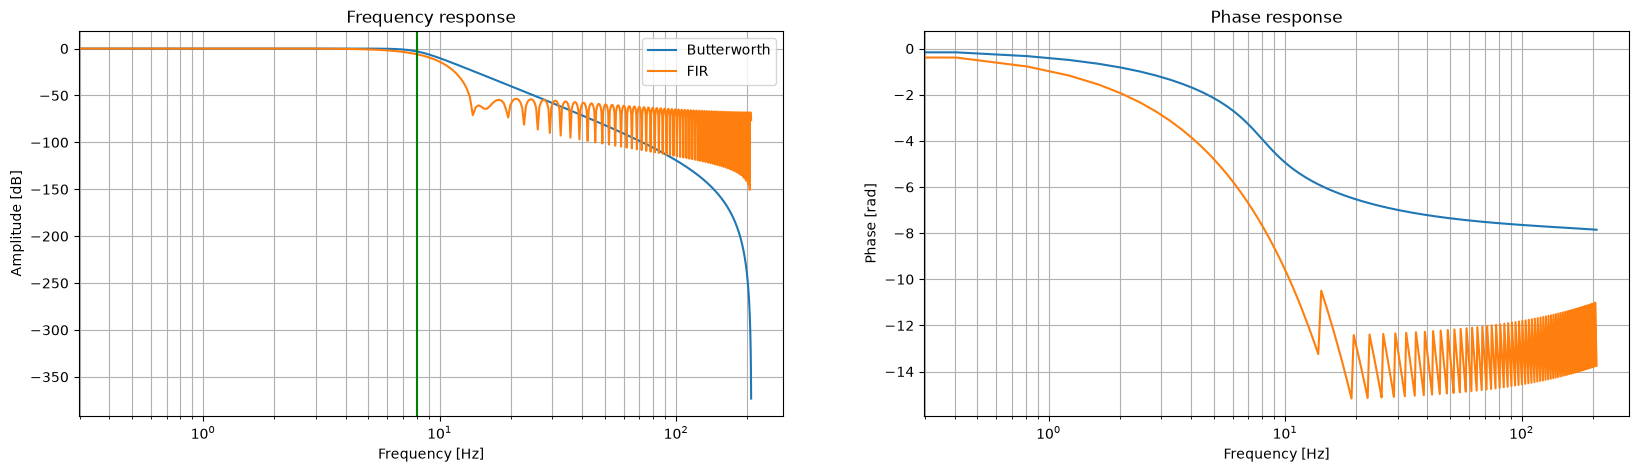

In [27]:
fs = 416
cutoff = 8
order = 5

fir_taps = 128

nyq = 0.5 * fs
normal_cutoff = cutoff / nyq
b, a = signal.butter(order, normal_cutoff, btype='low')
b2 = signal.firwin(fir_taps, cutoff, fs=fs)

w, h = signal.freqz(b, a, fs=fs)
w2, h2 = signal.freqz(b2, fs=fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5))

ax1.semilogx(w, 20 * np.log10(np.abs(h)), label='Butterworth')
ax1.semilogx(w2, 20 * np.log10(np.abs(h2)), label='FIR')
ax1.set_title('Frequency response')
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel('Amplitude [dB]')
ax1.grid(which='both', axis='both')
ax1.axvline(cutoff, color='green')
ax1.legend()

phase = np.unwrap(np.angle(h))
phase2 = np.unwrap(np.angle(h2))

ax2.semilogx(w, phase)
ax2.semilogx(w2, phase2)
ax2.set_title('Phase response')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Phase [rad]')
ax2.grid(which='both', axis='both')
ax2.grid(True)
ax2.axis('tight')


Test this on some real data

In [28]:
file = "260829_take2"
accel = pd.read_csv(f"../../data/cleaned/{file}.csv", index_col="frame")
accel_raw = accel["az"]

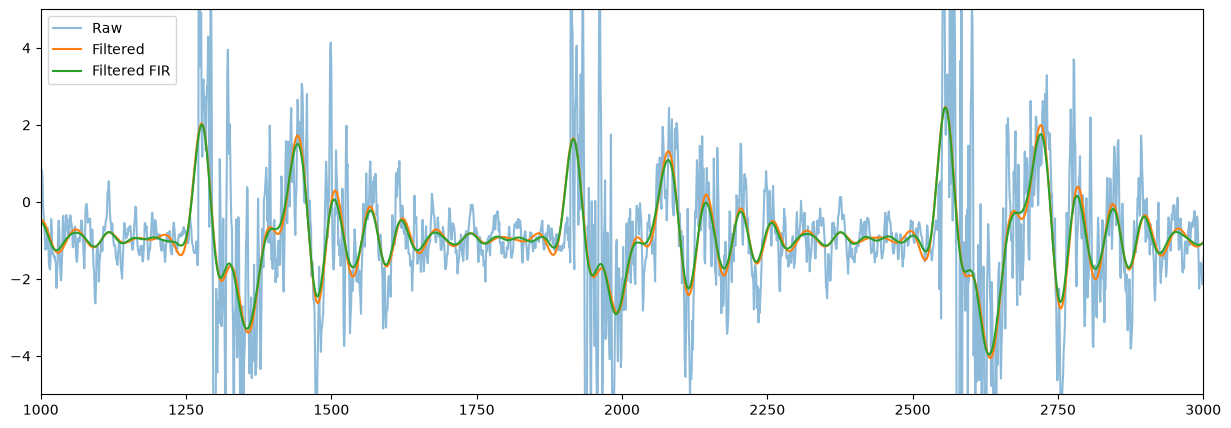

In [31]:
accel_filtered = signal.filtfilt(b, a, accel_raw) # butter filter, zero-phase filtering
accel_filtered2 = signal.lfilter(b2, 1, accel_raw) # fir filter, causal filtering

fir_delay = fir_taps // 2
# fir_delay = 0 # for comparison, set to 0 to see the delay of the FIR filter

plt.figure(figsize=(15, 5))
plt.plot(accel_raw, label='Raw', alpha=0.5)
plt.plot(accel_filtered, label='Filtered')
plt.plot(accel_filtered2[fir_delay::], label='Filtered FIR') # compensate for FIR filter delay
plt.legend()
plt.xlim(1000, 3000)
plt.ylim(-5, 5)
plt.show()

Verify the delay by cross-correlating the two signals

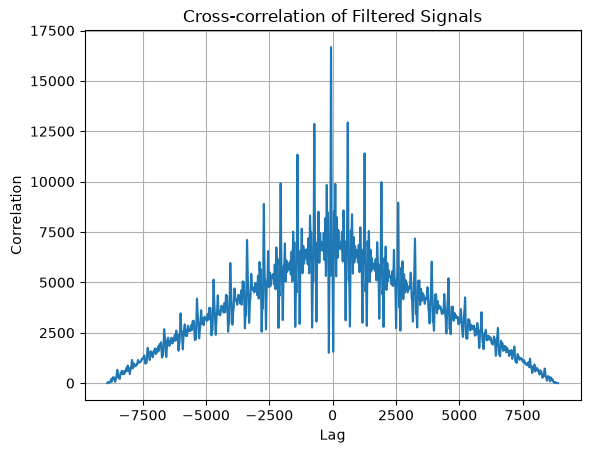

Delay: -63.5 samples


In [30]:
corr = signal.correlate(accel_filtered, accel_filtered2)
lags = signal.correlation_lags(len(accel_filtered), len(accel_filtered2))

plt.plot(lags, corr)
plt.xlabel('Lag')
plt.ylabel('Correlation')
plt.title('Cross-correlation of Filtered Signals')
plt.grid(True)
plt.show()

print(f"Delay: {np.argmax(corr)-len(corr)/2} samples")